In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score


In [3]:
pd.set_option('display.max_columns', None)


In [4]:
df = pd.read_csv('../data/processed/housing_data_engineered.csv', parse_dates=['date'])
print("Loaded data shape:", df.shape)
df[["city","zipcode","date","downturn_risk"]].head()

Loaded data shape: (262780, 64)


,city,zipcode,date,downturn_risk
0,BOS,1431,2013-03-31,0
1,BOS,1431,2013-04-30,0
2,BOS,1431,2013-05-31,0
3,BOS,1431,2013-06-30,0
4,BOS,1431,2013-07-31,0


In [5]:
id_cols = df[["date","city","zipcode"]]

In [6]:

y = df["downturn_risk"]

X = df.drop(columns=["downturn_risk", "date"])


In [7]:

X = pd.get_dummies(X, columns=['city', 'city_full'], drop_first=True)
X = X.astype(float)
non_numeric_cols = X.select_dtypes(exclude=['number']).columns
print(non_numeric_cols)

Index([], dtype='object')


In [8]:
#pca to reduce dimensionality to 6
print("\nRun PCA - [six dimensions]...")


Run PCA - [six dimensions]...


In [9]:

split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]
id_test = id_cols.iloc[split_index:]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=6)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
logreg.fit(X_train_pca, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [10]:
y_pred = logreg.predict(X_test_pca)
y_prob = logreg.predict_proba(X_test_pca)[:, 1]

print("Predictions:", y_pred[:10])
print("Probabilities:", y_prob[:10])

Predictions: [0 0 0 0 0 0 0 0 0 0]
Probabilities: [0.05989331 0.06021498 0.05703866 0.05757042 0.05406329 0.05316669
 0.05456029 0.05909717 0.06355324 0.06757062]


In [11]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC Score:")
print(roc_auc_score(y_test, y_prob))


Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.76      0.84     47218
           1       0.22      0.58      0.31      5338

    accuracy                           0.75     52556
   macro avg       0.58      0.67      0.58     52556
weighted avg       0.87      0.75      0.79     52556


Confusion Matrix:
[[36104 11114]
 [ 2268  3070]]

ROC-AUC Score:
0.727725006788741


In [12]:
threshold = 0.8
y_pred = (y_prob > threshold).astype(int)

In [13]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC Score:")
print(roc_auc_score(y_test, y_prob))


Classification Report:
              precision    recall  f1-score   support

           0       0.90      1.00      0.95     47218
           1       0.43      0.01      0.02      5338

    accuracy                           0.90     52556
   macro avg       0.67      0.50      0.48     52556
weighted avg       0.85      0.90      0.85     52556


Confusion Matrix:
[[47158    60]
 [ 5292    46]]

ROC-AUC Score:
0.727725006788741


In [14]:
results = id_test.copy()

results["actual"] = y_test.values
results["predicted"] = y_pred
results["probability"] = y_prob

In [15]:
results.to_csv("../data/result/housing_downturn_predictions.csv", index=False)

OSError: Cannot save file into a non-existent directory: '..\data\result'

In [ ]:
results.head()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

comparison = pd.DataFrame({
    "Actual": results["actual"].value_counts().sort_index(),
    "Predicted": results["predicted"].value_counts().sort_index()
})

comparison.index = ["No Downturn", "Downturn"]

comparison.plot(kind="bar", figsize=(8, 5))
plt.title("Actual vs Predicted Downturn Counts")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

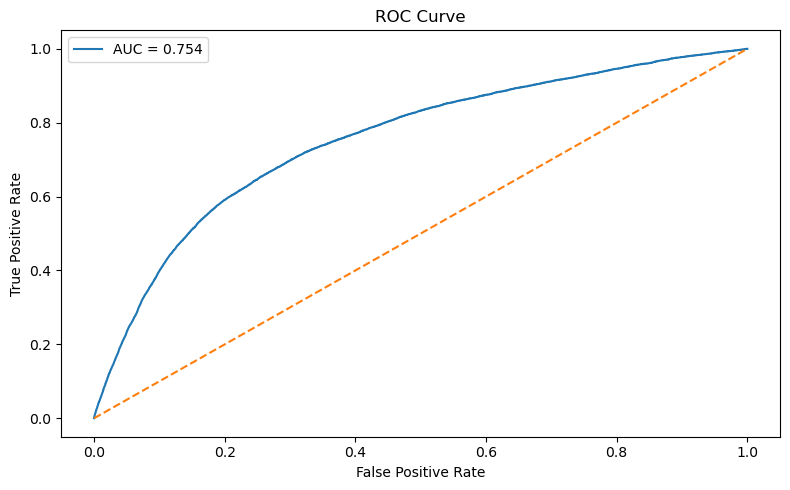

In [85]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()